In [ ]:

import pandas as pd
from google.colab import files
import io

# 1 - upload do CSV
arquivos = files.upload()

# 2 - abrir o arquivo como uma tabela
nome = next(iter(arquivos))
dados = pd.read_csv(
    io.BytesIO(arquivos[nome]),
    encoding="utf-8-sig"
)

# 3 - conferir a base
print("Total de documentos:", len(dados))
print("Quantidade de colunas:", len(dados.columns))

# 4 - mostrar as primeiras três publicações
display(dados[[
    "Title", "Year", "Affiliations", "Funding Details"
]].head(3))


Saving scopus_resfriamento_2000_2025.csv.csv to scopus_resfriamento_2000_2025.csv.csv
Total de documentos: 1366
Quantidade de colunas: 26


,Title,Year,Affiliations,Funding Details
0,Hierarchically Porous Superhydrophobic Thermop...,2025,National Engineering Research Center for Advan...,"Natural Science Foundation of Henan Province, ..."
1,Modeling of daytime radiative cooling enhanced...,2025,"Department of Energy, Politecnico di Torino, C...",European Union's Horizon Europe Research and I...
2,Double-Layer Coating Containing Boron Nitride ...,2025,Research Center for Materials Nanoarchitectoni...,Precursory Research for Embryonic Science and ...


In [ ]:
# 1 - identificar os artigos com financiamento declarado

dados["tem_financiamento"] = (
    dados["Funding Details"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

# 2 - contagem  dos resultados
total = len(dados)
com_financiamento = dados["tem_financiamento"].sum()
sem_financiamento = total - com_financiamento

# 3 - calculo de porcentagem
percentual = com_financiamento / total * 100

print("Total de artigos:", total)
print("Com financiamento declarado:", com_financiamento)
print("Sem financiamento declarado:", sem_financiamento)
print(f"Percentual: {percentual:.1f}%")


Total de artigos: 1366
Com financiamento declarado: 1200
Sem financiamento declarado: 166
Percentual: 87.8%


In [ ]:

# 1 - função para identificar os países
def extrair_paises(afiliacoes):

    if pd.isna(afiliacoes):
        return []

    paises = []

    for instituicao in str(afiliacoes).split(";"):

        pais = instituicao.rsplit(",", 1)[-1].strip()

        if pais and pais not in paises:
            paises.append(pais)

    return paises

# 2 - aplicar a função a todos
dados["paises"] = dados["Affiliations"].apply(extrair_paises)

display(dados[["Title", "paises"]].head(5))

contagem = dados.explode("paises")["paises"].value_counts()

print("Dez valores mais frequentes:")
print(contagem.head(10))

print("Artigos sem país identificado:",
      (dados["paises"].str.len() == 0).sum())


,Title,paises
0,Hierarchically Porous Superhydrophobic Thermop...,[China]
1,Modeling of daytime radiative cooling enhanced...,[Italy]
2,Double-Layer Coating Containing Boron Nitride ...,[Japan]
3,Modeling and performance evaluation of radiati...,[China]
4,Experimental and Numerical Investigation of th...,"[China, Hong Kong]"


Dez valores mais frequentes:
paises
China             920
United States     197
South Korea        85
Hong Kong          83
India              42
Australia          40
United Kingdom     39
Singapore          36
Italy              30
Spain              28
Name: count, dtype: int64
Artigos sem país identificado: 1


In [ ]:

# listar os países identificados
todos_paises = dados.explode("paises")["paises"].value_counts()

print("Quantidade de nomes diferentes:", len(todos_paises))

# mostrar os valores
print("Valores menos frequentes:")
display(todos_paises[todos_paises <= 2])


Quantidade de nomes diferentes: 63
Valores menos frequentes:


,count
paises,
Bangladesh,2
Qatar,2
Slovenia,2
Austria,2
Rwanda,1
South Africa,1
Kazakhstan,1
Optimization and CAE Software for Industrial Equipment,1
a. College of Textile Science and Engineering b. Engineering Research Center for Eco⁃Dyeing & Finishing of Textiles Ministry of Education c. Key Laboratory of Advanced Textile Materials and Manufacturing Technology Ministry of Education Zhejiang Sci⁃Tech University Hangzhou 310018 China,1


In [ ]:

# corrigir afiliações mal formatadas

correcoes = {
    "2-s2.0-86000432474": [
        "China", "Singapore", "United Kingdom"
    ],
    "2-s2.0-85180259058": ["China"],
    "2-s2.0-85084329567": ["Morocco"],
    "2-s2.0-85129693896": ["China"]
}

# preservar a classificação original
dados["paises_corrigidos"] = dados["paises"].copy()

# aplicar as correções
for eid, paises in correcoes.items():

    linhas = dados.index[dados["EID"] == eid]

    if len(linhas) == 1:
        dados.at[linhas[0], "paises_corrigidos"] = paises
    else:
        print("Verificar artigo:", eid)

# conferir
contagem_corrigida = (
    dados.explode("paises_corrigidos")
    ["paises_corrigidos"]
    .value_counts()
)

print("Países e territórios diferentes:",
      len(contagem_corrigida))

print("\nDez mais frequentes:")
print(contagem_corrigida.head(10))

print("\nArtigos sem país identificado:",
      (dados["paises_corrigidos"].str.len() == 0).sum())


Países e territórios diferentes: 58

Dez mais frequentes:
paises_corrigidos
China             921
United States     197
South Korea        85
Hong Kong          83
India              42
Australia          40
United Kingdom     39
Singapore          36
Italy              30
Spain              28
Name: count, dtype: int64

Artigos sem país identificado: 1


In [ ]:

# separar por país
base_paises = dados.explode("paises_corrigidos")

# retirar linhas sem país identificado
base_paises = base_paises.dropna(
    subset=["paises_corrigidos"]
)

# agrupar os registros
resultado = base_paises.groupby("paises_corrigidos").agg(
    total_artigos=("EID", "nunique"),
    com_financiamento=("tem_financiamento", "sum")
)

# calcular a porcentagem de financiamento
resultado["percentual"] = (
    resultado["com_financiamento"]
    / resultado["total_artigos"] * 100
).round(1)

# ordenar pelo número de artigos
resultado = resultado.sort_values(
    "total_artigos", ascending=False
)

# mostrar os dez países com mais publicações
display(resultado.head(10))


,total_artigos,com_financiamento,percentual
paises_corrigidos,,,
China,921,851,92.4
United States,197,157,79.7
South Korea,85,82,96.5
Hong Kong,83,81,97.6
India,42,20,47.6
Australia,40,33,82.5
United Kingdom,39,37,94.9
Singapore,36,36,100.0
Italy,30,24,80.0


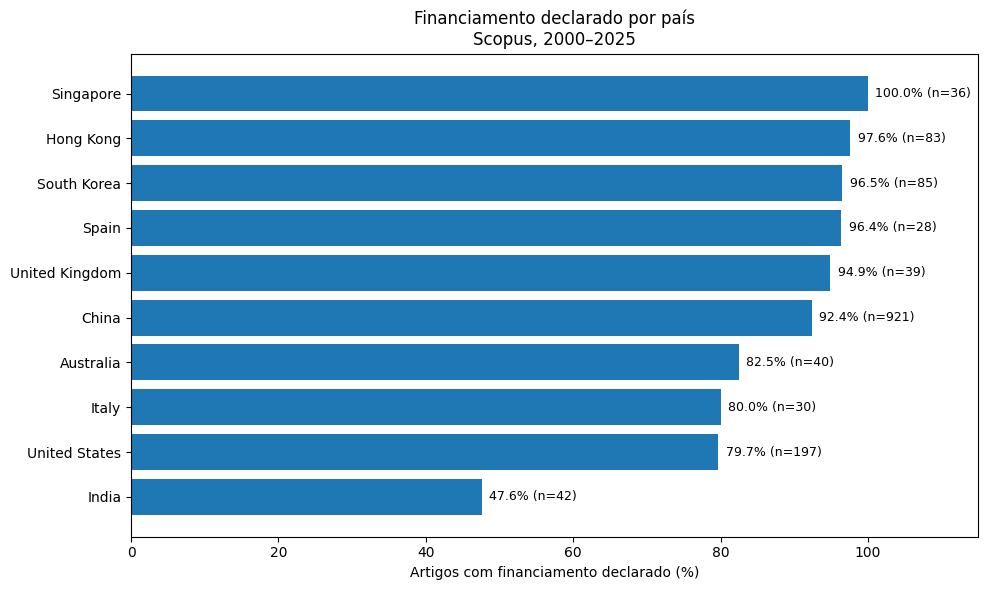

In [ ]:

import matplotlib.pyplot as plt

# selecionar países com mais artigos
top10 = resultado.head(10)

# organizar pelo percentual
top10 = top10.sort_values("percentual")

# criar o gráfico
fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    top10.index,
    top10["percentual"]
)

# adicionar as porcentagens e quantidades
for barra, (_, linha) in zip(barras, top10.iterrows()):
    ax.text(
        linha["percentual"] + 1,
        barra.get_y() + barra.get_height() / 2,
        f'{linha["percentual"]:.1f}% (n={linha["total_artigos"]:.0f})',
        va="center",
        fontsize=9
    )

# identificar o gráfico
ax.set_xlabel("Artigos com financiamento declarado (%)")
ax.set_title(
    "Financiamento declarado por país\n"
    "Scopus, 2000–2025"
)

ax.set_xlim(0, 115)

plt.tight_layout()

# salvar a imagem
plt.savefig(
    "grafico_financiamento_pais.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# conferir artigos associados a china

china_antes = dados["paises"].apply(
    lambda lista: "China" in lista
)

china_depois = dados["paises_corrigidos"].apply(
    lambda lista: "China" in lista
)

print("China antes da correção:", china_antes.sum())
print("China depois da correção:", china_depois.sum())
print("China no filtro do Scopus: 919")

# identificar os registros que mudaram
mudancas = dados.loc[
    china_antes != china_depois,
    ["EID", "Title", "paises", "paises_corrigidos"]
]

print("\nArtigos cuja classificação mudou:")
display(mudancas)

# conferir duplicados
print("EIDs duplicados:", dados["EID"].duplicated().sum())


China antes da correção: 920
China depois da correção: 921
China no filtro do Scopus: 919

Artigos cuja classificação mudou:


,EID,Title,paises,paises_corrigidos
537,2-s2.0-85180259058,Preparation and properties of superhydrophobic...,[a. College of Textile Science and Engineering...,[China]


EIDs duplicados: 0


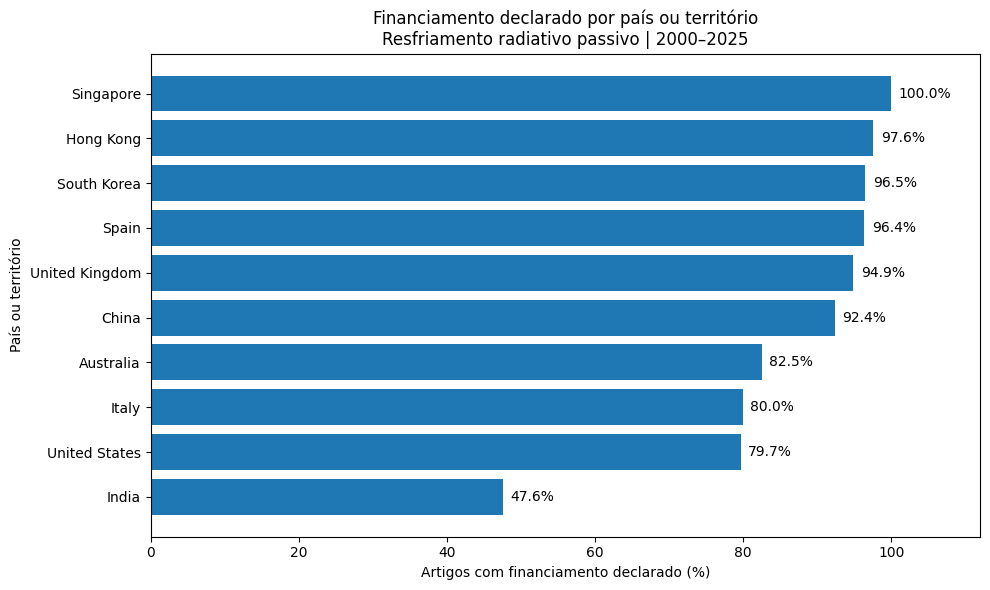

In [ ]:

import matplotlib.pyplot as plt

# selecionar os 10 países
top10 = resultado.head(10).copy()

# ordenar pelo percentual
top10 = top10.sort_values("percentual")

# criar grafico
fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    top10.index,
    top10["percentual"]
)

for barra, (_, linha) in zip(barras, top10.iterrows()):
    ax.text(
        linha["percentual"] + 1,
        barra.get_y() + barra.get_height() / 2,
        f'{linha["percentual"]:.1f}%',
        va="center"
    )

ax.set_xlim(0, 112)

ax.set_xlabel("Artigos com financiamento declarado (%)")
ax.set_ylabel("País ou território")

ax.set_title(
    "Financiamento declarado por país ou território\n"
    "Resfriamento radiativo passivo | 2000–2025"
)

plt.tight_layout()

plt.savefig(
    "grafico_financiamento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# exportar
resultado.to_csv(
    "financiamento_por_pais.csv",
    encoding="utf-8-sig"
)

print("Tabela salva com sucesso!")


Tabela salva com sucesso!


In [11]:

# artigos publicados entre 2015 e 2025
base_recente = base_paises[
    base_paises["Year"].between(2015, 2025)
].copy()

# calcular financiamento
resultado_recente = base_recente.groupby(
    "paises_corrigidos"
).agg(
    total_artigos=("EID", "nunique"),
    com_financiamento=("tem_financiamento", "sum")
)

resultado_recente["percentual"] = (
    resultado_recente["com_financiamento"]
    / resultado_recente["total_artigos"] * 100
).round(1)

# comparar com os dez países mais produtivos
paises_top10 = resultado.head(10).index

comparacao = pd.DataFrame({
    "2000-2025 (%)": resultado.loc[
        paises_top10, "percentual"
    ],
    "2015-2025 (%)": resultado_recente.reindex(
        paises_top10
    )["percentual"]
})

display(comparacao)


,2000-2025 (%),2015-2025 (%)
paises_corrigidos,,
China,92.4,92.4
United States,79.7,84.2
South Korea,96.5,96.5
Hong Kong,97.6,98.8
India,47.6,47.6
Australia,82.5,84.6
United Kingdom,94.9,97.3
Singapore,100.0,100.0
Italy,80.0,82.8


In [12]:

top10 = resultado.head(10).index

tabela_final = pd.DataFrame({
    "Total 2000-2025": resultado.loc[
        top10, "total_artigos"
    ],
    "Financiados 2000-2025": resultado.loc[
        top10, "com_financiamento"
    ],
    "Percentual 2000-2025": resultado.loc[
        top10, "percentual"
    ],
    "Total 2015-2025": resultado_recente.reindex(
        top10
    )["total_artigos"],
    "Financiados 2015-2025": resultado_recente.reindex(
        top10
    )["com_financiamento"],
    "Percentual 2015-2025": resultado_recente.reindex(
        top10
    )["percentual"]
})

display(tabela_final)

tabela_final.to_csv(
    "comparacao_financiamento_periodos.csv",
    encoding="utf-8-sig"
)

print("Tabela comparativa salva!")


,Total 2000-2025,Financiados 2000-2025,Percentual 2000-2025,Total 2015-2025,Financiados 2015-2025,Percentual 2015-2025
paises_corrigidos,,,,,,
China,921,851,92.4,920,850,92.4
United States,197,157,79.7,184,155,84.2
South Korea,85,82,96.5,85,82,96.5
Hong Kong,83,81,97.6,82,81,98.8
India,42,20,47.6,42,20,47.6
Australia,40,33,82.5,39,33,84.6
United Kingdom,39,37,94.9,37,36,97.3
Singapore,36,36,100.0,36,36,100.0
Italy,30,24,80.0,29,24,82.8


Tabela comparativa salva!


In [13]:


tabela_final = resultado.head(10).copy()

tabela_final = tabela_final.rename(columns={
    "total_artigos": "Total de artigos",
    "com_financiamento": "Com financiamento declarado",
    "percentual": "Percentual (%)"
})

tabela_final.index.name = "País ou território"

display(tabela_final)

tabela_final.to_csv(
    "financiamento_por_pais_final.csv",
    encoding="utf-8-sig"
)

print("Tabela final salva!")


,Total de artigos,Com financiamento declarado,Percentual (%)
País ou território,,,
China,921,851,92.4
United States,197,157,79.7
South Korea,85,82,96.5
Hong Kong,83,81,97.6
India,42,20,47.6
Australia,40,33,82.5
United Kingdom,39,37,94.9
Singapore,36,36,100.0
Italy,30,24,80.0


Tabela final salva!


In [14]:

from google.colab import files

files.download("financiamento_por_pais_final.csv")
files.download("grafico_financiamento.png")
files.download("comparacao_financiamento_periodos.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Análise do financiamento declarado por país

**Metodologia**

Foram analisados 1.366 registros bibliográficos da base Scopus, referentes ao período de 2000 a 2025, selecionados por meio de expressões relacionadas ao resfriamento radiativo passivo. Os dados foram processados em Python, utilizando as bibliotecas pandas e matplotlib.

Os países e territórios foram identificados a partir das afiliações institucionais dos autores. Foram realizadas correções pontuais em registros com problemas de formatação. Publicações com instituições de diferentes países foram contabilizadas em cada país correspondente.

Para calcular a proporção de financiamento declarado, foi dividido o número de publicações com o campo *Funding Details* preenchido pelo total de publicações associadas a cada país, multiplicando-se o resultado por 100.

**Resultados**

Dos 1.366 documentos analisados, 1.200 apresentaram informações de financiamento, correspondendo a 87,8% da base.

A China apresentou o maior volume de publicações, com 921 registros, dos quais 92,4% possuíam financiamento declarado. Os Estados Unidos apresentaram 79,7%, enquanto a Coreia do Sul alcançou 96,5%.

Entre os dez países e territórios mais produtivos, Singapura apresentou 100% dos artigos com financiamento declarado, enquanto a Índia apresentou o menor percentual, de 47,6%.

A comparação complementar com o período 2015–2025 indicou pequenas alterações para a maioria dos países analisados, embora os Estados Unidos tenham apresentado aumento de 79,7% para 84,2%.

**Limitações**

O indicador não representa o volume de recursos financeiros investidos, mas a presença de informações de financiamento nos registros da Scopus. A ausência dessa informação não significa necessariamente ausência de apoio financeiro.

A cobertura histórica dos metadados de financiamento pode influenciar as comparações entre períodos. Além disso, a atribuição de artigos com colaboração internacional a mais de um país produz contagens não exclusivas.

A classificação geográfica foi corrigida pontualmente, mas permanece uma diferença de dois registros entre a contagem da China obtida pelo processamento em Python e aquela apresentada pelo filtro da Scopus. Essa divergência deve ser considerada na interpretação dos resultados.
